# CFAR ship detection on xView3-SAR: multi-scene evaluation

This notebook extends the two-scene benchmark (`cfar_xview3_benchmark.ipynb`) to every scene of the xView3-SAR validation set.

## Pre-registered protocol (committed to the repository before any of these scenes were run)

1. **Detectors and thresholds are locked** exactly as in the two-scene benchmark: 2D CA-CFAR (guard 9, background 25, T = 11.6 dB), Hollow OS-CFAR (guard 9, outer 21, 85th percentile, T = 8.1 dB), Two-Parameter CFAR (T = 5.5 σ), plus the low reference threshold T = 5.0 dB for CA and OS. They were chosen on scene `590dd08f71056cacv` (calibration) and are **not changed** here.
2. **Scenes:** every scene in the validation link file that has labels in `validation.csv`, except the calibration scene. No scene is dropped after seeing its results. Scenes that cannot be evaluated (no labelled vessel, download or read error) are listed with the reason.
3. **Scene `b1844cde847a3942v`** (the test scene of the two-scene benchmark) is included and flagged, so results can also be reported on the fully new scenes only.
4. **Per scene:** same window rule (6000 × 6000 px centred on the median labelled-vessel position), same water mask, same preprocessing, matching (Hungarian, 20 px) and ignore rules as the two-scene benchmark.
5. **Primary result:** pooled precision, recall and F1 (TP, FP and FN summed over scenes) of 2D CA-CFAR at the locked threshold, all evaluated vessels, with 95% Wilson intervals.
6. **Secondary results:** the same for the other operating points and for HIGH-confidence labels; the per-scene F1 distribution; the best threshold on each scene from a sweep (CA and OS only), to measure how far the optimum moves between scenes. Best-on-scene values are optimistic and reported as such.

## How to run

1. On the xView3 download page, get a fresh `validation.txt` (VALIDATION SET button) and `validation.csv`.
2. Run all cells. The upload cell asks for these two files. Signed links are never printed or saved in the notebook.
3. Each scene is downloaded, reduced to the two files needed (`VH_dB.tif`, `owiMask.tif`), evaluated and deleted. Results are appended to `multiscene_results.csv` and `multiscene_sweeps.csv` after every scene and copied to one Google Drive folder (`MyDrive/xview3_multiscene_results`), so an interrupted run, even one whose runtime was lost, resumes by running all cells again.


In [1]:
!pip -q install rasterio scipy pandas matplotlib

## 1. Locked configuration and helper functions

In [2]:
# Same configuration and helper functions as cfar_xview3_benchmark.ipynb (locked).
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from scipy.ndimage import (
    median_filter, percentile_filter, uniform_filter,
    label, find_objects, binary_closing,
)
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------------------
# Locked configuration. Thresholds were chosen on scene 1 (calibration).
# ---------------------------------------------------------------------
CONFIG = {
    "data_dir": ".",                       # folder that contains one sub-folder per scene id
    "csv_path": "./validation.csv",
    "calibration_scene": "590dd08f71056cacv",   # scene 1: thresholds chosen here
    "test_scene": "b1844cde847a3942v",          # scene 2: run once with locked thresholds
    "crop_size": 6000,                     # window (pixels) centred on the median vessel position
    "nan_fill_db": -30.0,                  # value used for missing SAR pixels
    "brightness_floor_db": -30.0,          # absolute brightness cut-off (effectively off)
    "median_filter_size": 3,
    "closing_kernel": (5, 5),              # note: closing slightly erodes objects touching the window edge
    "min_cluster_area": 3,                 # minimum bounding-box area in pixels
    "match_distance_px": 20.0,             # matching radius (20 px = 200 m)

    "ca_guard_win": 9,
    "ca_bg_win": 25,
    "ca_locked_T_db": 11.6,                # scene-1 optimum was the grid point 11.571

    "os_guard_win": 9,
    "os_outer_win": 21,
    "os_percentile": 85,
    "os_locked_T_db": 8.1,                 # scene-1 optimum was the grid point 8.143

    "twoparam_locked_T_std": 5.5,
    "ref_low_T_db": 5.0,                   # low-threshold, high-recall reference point

    "db_sweep_grid": np.linspace(3.0, 15.0, 15),
    "std_sweep_grid": np.linspace(2.0, 9.0, 15),
}


def prepare_scene(df, scene_id, cfg):
    """Load a window of the scene, build detector background maps and ground-truth lists."""
    scene_dir = os.path.join(cfg["data_dir"], scene_id)
    rows = df[df["scene_id"] == scene_id].copy()
    vessels = rows[rows["is_vessel"] == True]
    med_r = int(vessels["detect_scene_row"].median())
    med_c = int(vessels["detect_scene_column"].median())
    crop = cfg["crop_size"]

    with rasterio.open(os.path.join(scene_dir, "VH_dB.tif")) as src:
        r_off = max(0, min(src.height - crop, med_r - crop // 2))
        c_off = max(0, min(src.width - crop, med_c - crop // 2))
        win = Window(c_off, r_off, crop, crop)
        vh_db = np.nan_to_num(src.read(1, window=win).astype(np.float32), nan=cfg["nan_fill_db"])
        full_w, full_h = src.width, src.height

    with rasterio.open(os.path.join(scene_dir, "owiMask.tif")) as owi:
        sx, sy = owi.width / full_w, owi.height / full_h
        owin = Window(c_off * sx, r_off * sy, crop * sx, crop * sy)
        water_mask = owi.read(1, window=owin, out_shape=(crop, crop)) == 0

    in_win = rows[
        (rows["detect_scene_row"] >= r_off) & (rows["detect_scene_row"] < r_off + crop) &
        (rows["detect_scene_column"] >= c_off) & (rows["detect_scene_column"] < c_off + crop)
    ].copy().reset_index(drop=True)
    in_win["local_row"] = in_win["detect_scene_row"] - r_off
    in_win["local_col"] = in_win["detect_scene_column"] - c_off
    ri = in_win["local_row"].astype(int).clip(0, crop - 1).values
    ci = in_win["local_col"].astype(int).clip(0, crop - 1).values
    in_win["in_water_mask"] = water_mask[ri, ci]

    win_vessels = in_win[in_win["is_vessel"] == True]
    water_rec = in_win[in_win["in_water_mask"]].reset_index(drop=True)
    eval_vessels = water_rec[water_rec["is_vessel"] == True].reset_index(drop=True)
    high = eval_vessels[eval_vessels["confidence"] == "HIGH"]

    cols = ["local_row", "local_col"]
    not_vessel = water_rec["is_vessel"] != True
    not_high = water_rec["confidence"] != "HIGH"

    # detector background maps
    vh_clean = median_filter(vh_db, size=cfg["median_filter_size"])
    bg_w, gd_w = cfg["ca_bg_win"], cfg["ca_guard_win"]
    n_bg = bg_w ** 2 - gd_w ** 2
    ca_bg = (uniform_filter(vh_clean, size=bg_w) * bg_w ** 2
             - uniform_filter(vh_clean, size=gd_w) * gd_w ** 2) / n_bg
    sq = (uniform_filter(vh_clean ** 2, size=bg_w) * bg_w ** 2
          - uniform_filter(vh_clean ** 2, size=gd_w) * gd_w ** 2) / n_bg
    ca_std = np.sqrt(np.maximum(sq - ca_bg ** 2, 1e-4))

    out_w, os_gd = cfg["os_outer_win"], cfg["os_guard_win"]
    fp = np.ones((out_w, out_w), dtype=bool)
    pad = (out_w - os_gd) // 2
    fp[pad:pad + os_gd, pad:pad + os_gd] = False
    os_bg = percentile_filter(vh_clean, percentile=cfg["os_percentile"], footprint=fp)

    return {
        "scene_id": scene_id, "vh_clean": vh_clean, "ca_bg": ca_bg, "ca_std": ca_std,
        "os_bg": os_bg, "water_mask": water_mask,
        "n_window": len(win_vessels), "n_masked": int((~win_vessels["in_water_mask"]).sum()),
        "n_eval": len(eval_vessels), "n_high": len(high),
        "gt_all": eval_vessels[cols].values, "ig_all": water_rec[not_vessel][cols].values,
        "gt_high": high[cols].values, "ig_high": water_rec[not_vessel | not_high][cols].values,
    }


def extract_centroids(binary_mask, water_mask, cfg):
    """Closing + connected components; returns one centroid per candidate."""
    clean = binary_closing(binary_mask & water_mask, structure=np.ones(cfg["closing_kernel"]))
    lbl, _ = label(clean)
    pts = []
    for box in find_objects(lbl):
        area = (box[0].stop - box[0].start) * (box[1].stop - box[1].start)
        if area >= cfg["min_cluster_area"]:
            pts.append([(box[0].start + box[0].stop) / 2.0, (box[1].start + box[1].stop) / 2.0])
    return np.array(pts) if pts else np.empty((0, 2))


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    denom = 1.0 + z ** 2 / n
    center = (p + z ** 2 / (2.0 * n)) / denom
    half = z * np.sqrt(p * (1.0 - p) / n + z ** 2 / (4.0 * n ** 2)) / denom
    return max(0.0, center - half), min(1.0, center + half)


def evaluate_predictions(pred, target_gt, ignore_gt, max_dist=20.0):
    """One-to-one matching. Predictions near an 'ignore' object are not counted as false alarms."""
    if len(pred) == 0:
        return 0, 0, len(target_gt), 0.0, 0.0, 0.0
    if len(target_gt) == 0:
        return 0, len(pred), 0, 0.0, 0.0, 0.0
    d = cdist(pred, target_gt)
    p_idx, g_idx = linear_sum_assignment(d)
    matched = {p for p, g in zip(p_idx, g_idx) if d[p, g] <= max_dist}
    rest = [i for i in range(len(pred)) if i not in matched]
    ignored = 0
    if rest and len(ignore_gt) > 0:
        ignored = int((cdist(pred[rest], ignore_gt).min(axis=1) <= max_dist).sum())
    tp, fp = len(matched), len(rest) - ignored
    fn = len(target_gt) - tp
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return tp, fp, fn, prec, rec, f1


def detect(S, algo, T, cfg):
    """Binary detection mask for one algorithm at threshold T."""
    thr = algo["bg"] + (T * algo["std"] if algo["std"] is not None else T)
    return (S["vh_clean"] > thr) & (S["vh_clean"] > cfg["brightness_floor_db"])


def algo_table(S, cfg):
    return {
        "2D CA-CFAR": dict(bg=S["ca_bg"], std=None, grid=cfg["db_sweep_grid"],
                           locked=cfg["ca_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:red"),
        "Hollow OS-CFAR": dict(bg=S["os_bg"], std=None, grid=cfg["db_sweep_grid"],
                               locked=cfg["os_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:cyan"),
        "Two-Param CFAR": dict(bg=S["ca_bg"], std=S["ca_std"], grid=cfg["std_sweep_grid"],
                               locked=cfg["twoparam_locked_T_std"], ref=None, color="tab:orange"),
    }


def eval_both(S, pts, cfg):
    md_ = cfg["match_distance_px"]
    return (evaluate_predictions(pts, S["gt_all"], S["ig_all"], md_),
            evaluate_predictions(pts, S["gt_high"], S["ig_high"], md_))


def print_table(title, rows):
    print(title)
    print("-" * 104)
    print(f"{'OPERATING POINT':<36}| {'TP':<4}| {'FP':<5}| {'FN':<4}| {'PRECISION (95% CI)':<22}| {'RECALL (95% CI)':<22}| F1")
    print("-" * 104)
    for name, (tp, fp, fn, prec, rec, f1) in rows:
        pl, ph = wilson_ci(tp, tp + fp)
        rl, rh = wilson_ci(tp, tp + fn)
        print(f"{name:<36}| {tp:<4}| {fp:<5}| {fn:<4}| {prec*100:5.1f}% ({pl*100:4.1f}-{ph*100:4.1f})  "
              f"| {rec*100:5.1f}% ({rl*100:4.1f}-{rh*100:4.1f})  | {f1*100:5.1f}%")
    print()


## 2. Input files

In [3]:
import os, glob, shutil
LINKS_FILE = "validation.txt"
LABELS_FILE = os.path.basename(CONFIG["csv_path"])   # validation.csv

def normalise_names():
    """Browsers may save downloads as 'validation (1).csv' etc. Copy them to the expected names."""
    for target, pattern in [(LINKS_FILE, "validation*.txt"), (LABELS_FILE, "validation*.csv")]:
        if not os.path.exists(target):
            found = sorted(glob.glob(pattern), key=os.path.getmtime)
            if found:
                shutil.copy(found[-1], target)

normalise_names()
missing = [f for f in [LINKS_FILE, LABELS_FILE] if not os.path.exists(f)]
if missing:
    from google.colab import files
    print("Select these files:", ", ".join(missing))
    files.upload()   # file contents are not printed
    normalise_names()
for f in [LINKS_FILE, LABELS_FILE]:
    print(f, "present:", os.path.exists(f))
assert all(os.path.exists(f) for f in [LINKS_FILE, LABELS_FILE]), "Upload both validation.txt and validation.csv, then run again."


Select these files: validation.txt, validation.csv


Saving validation.csv to validation.csv
Saving validation.txt to validation.txt
validation.txt present: True
validation.csv present: True


## 3. Backup to Google Drive

In [4]:
# Backup of the small result CSVs (a few KB per scene) to one Google Drive folder,
# so a run whose Colab runtime is lost can resume. Only this folder is written to; nothing in Drive is deleted.
import shutil
from google.colab import drive
drive.mount("/content/drive")
BACKUP_DIR = "/content/drive/MyDrive/xview3_multiscene_results"
os.makedirs(BACKUP_DIR, exist_ok=True)
RESULT_FILES = ["multiscene_results.csv", "multiscene_sweeps.csv", "multiscene_skipped.csv"]

for name in RESULT_FILES:
    backup = os.path.join(BACKUP_DIR, name)
    if os.path.exists(backup) and not os.path.exists(name):
        shutil.copy(backup, name)
        print("Restored", name, "from Drive")

def backup_results():
    for name in RESULT_FILES:
        if os.path.exists(name):
            shutil.copy(name, os.path.join(BACKUP_DIR, name))

print("Backup folder:", BACKUP_DIR)


Mounted at /content/drive
Restored multiscene_results.csv from Drive
Restored multiscene_sweeps.csv from Drive
Backup folder: /content/drive/MyDrive/xview3_multiscene_results


## 4. Evaluate every scene (resumable)

In [5]:
import subprocess, shutil, time

RESULTS_CSV = "multiscene_results.csv"
SWEEP_CSV = "multiscene_sweeps.csv"
SKIPPED_CSV = "multiscene_skipped.csv"
PREVIOUS_TEST_SCENE = CONFIG["test_scene"]

def scene_id_from_url(url):
    return url.split("?")[0].rstrip("/").split("/")[-1].replace(".tar.gz", "")

with open(LINKS_FILE) as f:
    url_by_scene = {}
    for line in f:
        line = line.strip()
        if line.startswith("https://"):
            url_by_scene[scene_id_from_url(line)] = line

df_val = pd.read_csv(CONFIG["csv_path"])
labelled = set(df_val["scene_id"].unique())
scene_ids = sorted(s for s in url_by_scene if s != CONFIG["calibration_scene"])
print(f"Scenes in link file: {len(url_by_scene)} | evaluated here (calibration scene excluded): {len(scene_ids)}")

def download_scene_minimal(scene_id, url, data_dir):
    """Download one scene and extract only VH_dB.tif and owiMask.tif. The signed link is never printed."""
    tar_path = os.path.join(data_dir, f"{scene_id}.tar.gz")
    try:
        subprocess.run(["wget", "-q", "-O", tar_path, url], check=True)
        subprocess.run(["tar", "-xzf", tar_path, "-C", data_dir, "--wildcards",
                        "*/VH_dB.tif", "*/owiMask.tif"], check=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"download/extract failed (exit code {e.returncode}); "
                           "the signed links may have expired, get a fresh validation.txt") from None
    finally:
        if os.path.exists(tar_path):
            os.remove(tar_path)

def done_scenes(path):
    return set(pd.read_csv(path)["scene_id"]) if os.path.exists(path) else set()

def append_rows(path, rows):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)
    globals().get("backup_results", lambda: None)()   # copy to Drive if the backup cell ran

already = done_scenes(RESULTS_CSV) | done_scenes(SKIPPED_CSV)
t_start = time.time()
for i, sid in enumerate(scene_ids, 1):
    if sid in already:
        continue
    t0 = time.time()
    tag = " (previous test scene)" if sid == PREVIOUS_TEST_SCENE else ""
    n_lab = int(((df_val["scene_id"] == sid) & (df_val["is_vessel"] == True)).sum())
    if sid not in labelled or n_lab == 0:
        append_rows(SKIPPED_CSV, [{"scene_id": sid, "reason": "no labelled vessels"}])
        print(f"[{i}/{len(scene_ids)}] {sid}: skipped (no labelled vessels)")
        continue
    try:
        download_scene_minimal(sid, url_by_scene[sid], CONFIG["data_dir"])
        S = prepare_scene(df_val, sid, CONFIG)
    except Exception as e:
        append_rows(SKIPPED_CSV, [{"scene_id": sid, "reason": str(e)[:200]}])
        print(f"[{i}/{len(scene_ids)}] {sid}: skipped ({str(e)[:120]})")
        shutil.rmtree(os.path.join(CONFIG["data_dir"], sid), ignore_errors=True)
        continue

    base = {"scene_id": sid, "previous_test_scene": sid == PREVIOUS_TEST_SCENE,
            "n_window": S["n_window"], "n_masked": S["n_masked"], "n_eval": S["n_eval"], "n_high": S["n_high"]}
    rows, sweeps = [], []
    for name, a in algo_table(S, CONFIG).items():
        points = [("locked", a["locked"])] + ([("ref", a["ref"])] if a["ref"] is not None else [])
        for kind, T in points:
            pts = extract_centroids(detect(S, a, T, CONFIG), S["water_mask"], CONFIG)
            r_all, r_high = eval_both(S, pts, CONFIG)
            rows.append({**base, "detector": name, "point": kind, "T": T,
                         "tp": r_all[0], "fp": r_all[1], "fn": r_all[2],
                         "tp_high": r_high[0], "fp_high": r_high[1], "fn_high": r_high[2]})
        if name != "Two-Param CFAR":
            for T in a["grid"]:
                pts = extract_centroids(detect(S, a, T, CONFIG), S["water_mask"], CONFIG)
                r_all = evaluate_predictions(pts, S["gt_all"], S["ig_all"], CONFIG["match_distance_px"])
                sweeps.append({"scene_id": sid, "detector": name, "T": round(float(T), 3),
                               "tp": r_all[0], "fp": r_all[1], "fn": r_all[2]})
    append_rows(RESULTS_CSV, rows)
    append_rows(SWEEP_CSV, sweeps)
    shutil.rmtree(os.path.join(CONFIG["data_dir"], sid), ignore_errors=True)
    del S

    ca = next(r for r in rows if r["detector"] == "2D CA-CFAR" and r["point"] == "locked")
    f1 = 2 * ca["tp"] / (2 * ca["tp"] + ca["fp"] + ca["fn"]) if ca["tp"] else 0.0
    print(f"[{i}/{len(scene_ids)}] {sid}{tag}: evaluated {base['n_eval']} (masked {base['n_masked']}) | "
          f"CA locked TP/FP/FN {ca['tp']}/{ca['fp']}/{ca['fn']} F1 {f1*100:.1f}% | {time.time()-t0:.0f} s")

print(f"\nDone in {(time.time()-t_start)/60:.1f} min.")


Scenes in link file: 50 | evaluated here (calibration scene excluded): 49

Done in 0.0 min.


## 5. Pooled results, per-scene spread and threshold drift

Scenes evaluated: 49 | skipped: 0
Labelled vessels in windows: 3058 | not evaluated (masked): 1416 (46%) | evaluated: 1642 (HIGH: 856)

POOLED OVER ALL EVALUATED SCENES: all evaluated vessels (N=1642)
--------------------------------------------------------------------------------------------------------
OPERATING POINT                     | TP  | FP   | FN  | PRECISION (95% CI)    | RECALL (95% CI)       | F1
--------------------------------------------------------------------------------------------------------
2D CA-CFAR (locked T=11.6)          | 990 | 298  | 652 |  76.9% (74.5-79.1)  |  60.3% (57.9-62.6)  |  67.6%
2D CA-CFAR (ref T=5.0)              | 1532| 17056| 110 |   8.2% ( 7.9- 8.6)  |  93.3% (92.0-94.4)  |  15.1%
Hollow OS-CFAR (locked T=8.1)       | 1111| 390  | 531 |  74.0% (71.7-76.2)  |  67.7% (65.4-69.9)  |  70.7%
Hollow OS-CFAR (ref T=5.0)          | 1471| 1621 | 171 |  47.6% (45.8-49.3)  |  89.6% (88.0-91.0)  |  62.1%
Two-Param CFAR (locked T=5.5)       | 894 | 966  

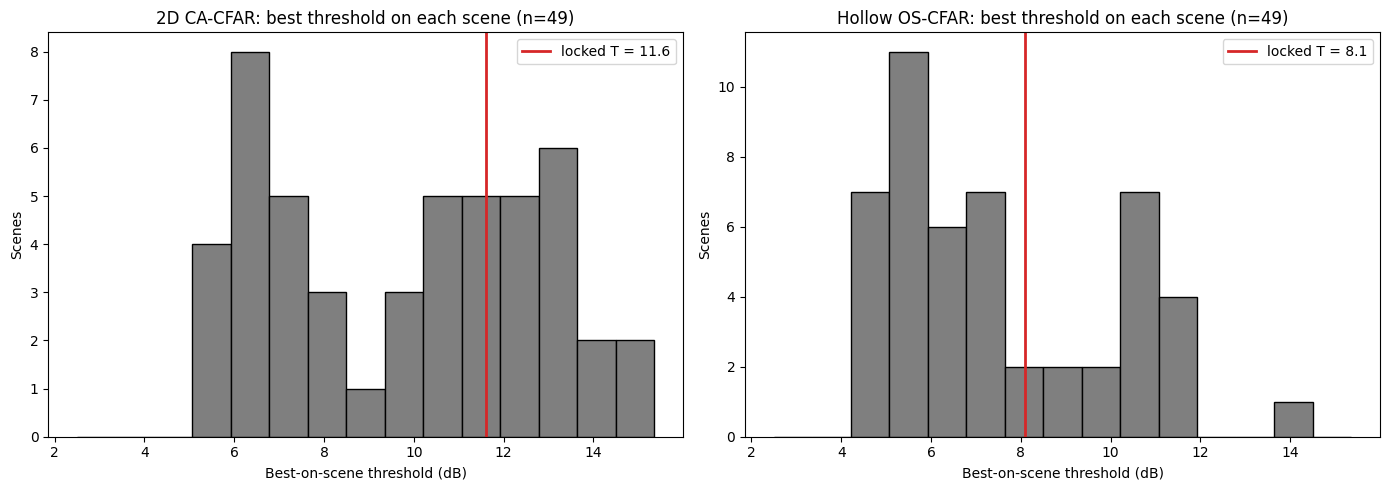

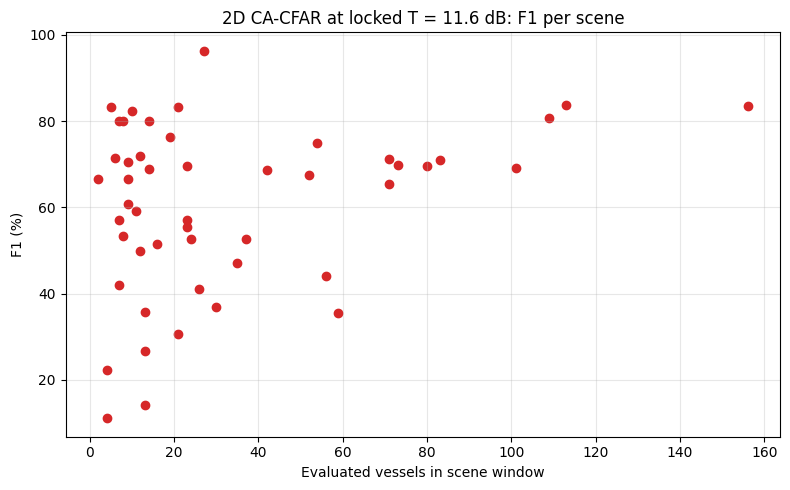

In [6]:
assert os.path.exists(RESULTS_CSV), "No scene has been evaluated yet; see the skipped list above."
res = pd.read_csv(RESULTS_CSV)
sw = pd.read_csv(SWEEP_CSV)
skipped = pd.read_csv(SKIPPED_CSV) if os.path.exists(SKIPPED_CSV) else pd.DataFrame(columns=["scene_id", "reason"])

def pooled_table(df, suffix="", title=""):
    rows = []
    for (det, point), g in df.groupby(["detector", "point"], sort=False):
        tp, fp, fn = int(g["tp" + suffix].sum()), int(g["fp" + suffix].sum()), int(g["fn" + suffix].sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        rows.append((f"{det} ({point} T={g['T'].iloc[0]})", (tp, fp, fn, prec, rec, f1)))
    print_table(title, rows)

one = res[(res["detector"] == "2D CA-CFAR") & (res["point"] == "locked")]
print(f"Scenes evaluated: {one['scene_id'].nunique()} | skipped: {len(skipped)}")
print(f"Labelled vessels in windows: {one['n_window'].sum()} | not evaluated (masked): {one['n_masked'].sum()} "
      f"({one['n_masked'].sum() / max(one['n_window'].sum(), 1) * 100:.0f}%) | evaluated: {one['n_eval'].sum()} "
      f"(HIGH: {one['n_high'].sum()})\n")
if len(skipped):
    print("Skipped scenes:")
    print(skipped.to_string(index=False), "\n")

pooled_table(res, "", f"POOLED OVER ALL EVALUATED SCENES: all evaluated vessels (N={one['n_eval'].sum()})")
pooled_table(res, "_high", f"POOLED OVER ALL EVALUATED SCENES: HIGH-confidence labels only (N={one['n_high'].sum()})")
new_only = res[~res["previous_test_scene"]]
pooled_table(new_only, "", "POOLED OVER NEW SCENES ONLY (previous test scene excluded): all evaluated vessels")

# per-scene F1 distribution at the locked thresholds
per_scene = res[res["point"] == "locked"].copy()
per_scene["f1"] = 2 * per_scene["tp"] / (2 * per_scene["tp"] + per_scene["fp"] + per_scene["fn"]).clip(lower=1)
print("Per-scene F1 at locked thresholds (all evaluated vessels):")
print(per_scene.groupby("detector")["f1"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "min", "25%", "50%", "75%", "max"]]
      .mul([1, 100, 100, 100, 100, 100]).round(1).to_string(), "\n")

# threshold drift: best threshold per scene (optimistic) and pooled optimum
sw["f1"] = 2 * sw["tp"] / (2 * sw["tp"] + sw["fp"] + sw["fn"]).clip(lower=1)
best = sw.loc[sw.groupby(["scene_id", "detector"])["f1"].idxmax()]
locked_T = {"2D CA-CFAR": CONFIG["ca_locked_T_db"], "Hollow OS-CFAR": CONFIG["os_locked_T_db"]}
for det, g in best.groupby("detector"):
    pooled = sw[sw["detector"] == det].groupby("T")[["tp", "fp", "fn"]].sum()
    pooled_f1 = 2 * pooled["tp"] / (2 * pooled["tp"] + pooled["fp"] + pooled["fn"])
    print(f"{det}: best-on-scene T median {g['T'].median():.1f} dB (IQR {g['T'].quantile(.25):.1f}-{g['T'].quantile(.75):.1f}), "
          f"locked T {locked_T[det]} | pooled F1 is highest at T={pooled_f1.idxmax():.1f} ({pooled_f1.max()*100:.1f}%, optimistic)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (det, g) in zip(axes, best.groupby("detector")):
    ax.hist(g["T"], bins=np.arange(2.5, 16, 0.857), color="tab:gray", edgecolor="black")
    ax.axvline(locked_T[det], color="tab:red", lw=2, label=f"locked T = {locked_T[det]}")
    ax.set_title(f"{det}: best threshold on each scene (n={len(g)})")
    ax.set_xlabel("Best-on-scene threshold (dB)"); ax.set_ylabel("Scenes"); ax.legend()
plt.tight_layout(); plt.savefig("multiscene_best_threshold_hist.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ca_ps = per_scene[per_scene["detector"] == "2D CA-CFAR"]
ax.scatter(ca_ps["n_eval"], ca_ps["f1"] * 100, color="tab:red")
ax.set_xlabel("Evaluated vessels in scene window"); ax.set_ylabel("F1 (%)")
ax.set_title("2D CA-CFAR at locked T = 11.6 dB: F1 per scene"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("multiscene_ca_f1_per_scene.png", dpi=150); plt.show()
